# **Utah Housing Market Anomaly Detection**
## **Author:** Tanner Rapp
### ** Data Source:** Redfin. (2025). Salt Lake City, UT homes for sale & real estate. Retrieved from https://www.redfin.com/city/17150/UT/Salt-Lake-City

### About the Dataset
---

The dataset was obtained from Redfin’s Salt Lake City housing listings, which include detailed real estate information on homes currently for sale or recently sold in the Utah region. The data features property attributes such as price, square footage, lot size, number of bedrooms and bathrooms, year built, and geographic coordinates. These features make the dataset well-suited for exploring housing market trends, building predictive models, and identifying spatial or pricing anomalies across the Salt Lake City metropolitan area.

### Libraries
---

In [22]:
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster
import numpy as np
from sklearn.linear_model import LinearRegression

### Load in the Data
--- 

**Note:** The Redfin housing data must be manually downloaded from the Redfin Salt Lake City listings page
 and saved in the specified folder. This script then automatically loads the most recently downloaded CSV file to ensure the analysis uses the latest available data. Please update the file path to wherever you downloaded the CSV files from Redfin. 

# 👇 

In [6]:
# Path to your folder containing Redfin CSVs
data_dir = Path(r"C:\Users\tanne\OneDrive\Desktop\Fun Statistical Coding Practice\Utah Housing Anomaly Detection")

In [31]:
# Find all Redfin CSV files
csv_files = list(data_dir.glob("redfin_*.csv"))

if not csv_files:
    raise FileNotFoundError("No Redfin CSV files found in the directory.")

# Sort by modification time (newest last)
latest_csv = max(csv_files, key=lambda f: f.stat().st_mtime)

# Read it
data = pd.read_csv(latest_csv)

print(f"Loaded latest Redfin file:\n{latest_csv.name}")

Loaded latest Redfin file:
redfin_2025-10-08-08-24-40.csv


In [32]:
# Preview Data
data.head()

,SALE TYPE,SOLD DATE,PROPERTY TYPE,ADDRESS,CITY,STATE OR PROVINCE,ZIP OR POSTAL CODE,PRICE,BEDS,BATHS,...,STATUS,NEXT OPEN HOUSE START TIME,NEXT OPEN HOUSE END TIME,URL (SEE https://www.redfin.com/buy-a-home/comparative-market-analysis FOR INFO ON PRICING),SOURCE,MLS#,FAVORITE,INTERESTED,LATITUDE,LONGITUDE
0,"In accordance with local MLS rules, some MLS l...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MLS Listing,NaN,Single Family Residential,557 N 1300 W,Salt Lake City,UT,84116.0,477500.0,4.0,2.0,...,Active,October-11-2025 11:00 AM,October-11-2025 01:00 PM,https://www.redfin.com/UT/Salt-Lake-City/557-N...,WFRMLS,2112155.0,N,Y,40.781601,-111.928742
2,MLS Listing,NaN,Single Family Residential,1371 E Zenith Ave,Salt Lake City,UT,84106.0,700000.0,5.0,2.5,...,Active,NaN,NaN,https://www.redfin.com/UT/Salt-Lake-City/1371-...,WFRMLS,2107061.0,N,Y,40.708050,-111.851441
3,MLS Listing,NaN,Condo/Co-op,555 E 100 S #206,Salt Lake City,UT,84102.0,325000.0,1.0,1.0,...,Active,NaN,NaN,https://www.redfin.com/UT/Salt-Lake-City/555-E...,WFRMLS,2096801.0,N,Y,40.767482,-111.874907
4,MLS Listing,NaN,Condo/Co-op,360 W 300 S #233,Salt Lake City,UT,84101.0,390500.0,1.0,1.0,...,Active,NaN,NaN,https://www.redfin.com/UT/Salt-Lake-City/360-W...,WFRMLS,2094934.0,N,Y,40.763116,-111.901503


### Data Prep
---

In [33]:
# Filter to price range
data = data[data['PRICE'] < 1000000]

In [34]:
# Set random seed for reproducibility
np.random.seed(42)

In [35]:
# Remove row that is unnessesary
data = data.iloc[1:]

In [36]:
# Filter out undesired property types
data = data[data['PROPERTY TYPE'].isin(['Single Family Residential','Condo/Co-op', 'Townhouse', 'Mobile/Manufactured Home', 'Other'])]

In [37]:
# Renamne complex URL column to just URL
data = data.rename(columns={'URL (SEE https://www.redfin.com/buy-a-home/comparative-market-analysis FOR INFO ON PRICING)': 'URL'})

In [38]:
# Impute missing HOA/MONTH values with the mean within each ZIP code to retain more data
data['HOA/MONTH'] = (data.groupby('ZIP OR POSTAL CODE')['HOA/MONTH'].transform(lambda x: x.fillna(x.mean())))

In [39]:
# Define which columns will be used
features = ['PRICE', 'BEDS', 'BATHS',
            'SQUARE FEET', 'LOT SIZE', 'YEAR BUILT', 'DAYS ON MARKET',
           'HOA/MONTH', 'LATITUDE', 'LONGITUDE', 'PROPERTY TYPE','CITY','URL']

df = data[features] # For later use

In [40]:
# Drop houses with missing data
data = data[features].dropna()

In [41]:
# Convert categorical features into numeric dummy variables for modeling
x_data_encoded = pd.get_dummies(data[['PROPERTY TYPE','CITY']], columns=['PROPERTY TYPE','CITY'], drop_first=True)

In [42]:
# Normalize features to ensure fair comparison and equal scaling across all variables
scaler = StandardScaler()

x_data = data.drop(columns = ['PRICE','PROPERTY TYPE','CITY','URL'])

x_scaled = pd.DataFrame(
    scaler.fit_transform(x_data),
    columns=x_data.columns,
    index=x_data.index
)

# Combine numeric (scaled) + categorical (encoded)
x = pd.concat([x_scaled, x_data_encoded], axis=1)


In [43]:
# Summary after filtering incomplete data
print("Missing values per feature (Showing what was filtered out):")
print(df.isna().sum())

print(f"\n✅ Dataset now contains {x.shape[0]:,} houses × {x.shape[1]:,} features (some of which are dummy variables) in the SLC Area")


Missing values per feature (Showing what was filtered out):
PRICE              0
BEDS               1
BATHS              0
SQUARE FEET        0
LOT SIZE           4
YEAR BUILT         0
DAYS ON MARKET     0
HOA/MONTH         28
LATITUDE           0
LONGITUDE          0
PROPERTY TYPE      0
CITY               0
URL                0
dtype: int64

✅ Dataset now contains 213 houses × 18 features (some of which are dummy variables) in the SLC Area


### Model Architecture
---

In [46]:
# Defining target and predictor variables
y = data['PRICE']
x = x

In [71]:
# Fit Multiple Linear Regression on full dataset
model = LinearRegression()
model.fit(x, y)

LinearRegression()

### Model Performance
---

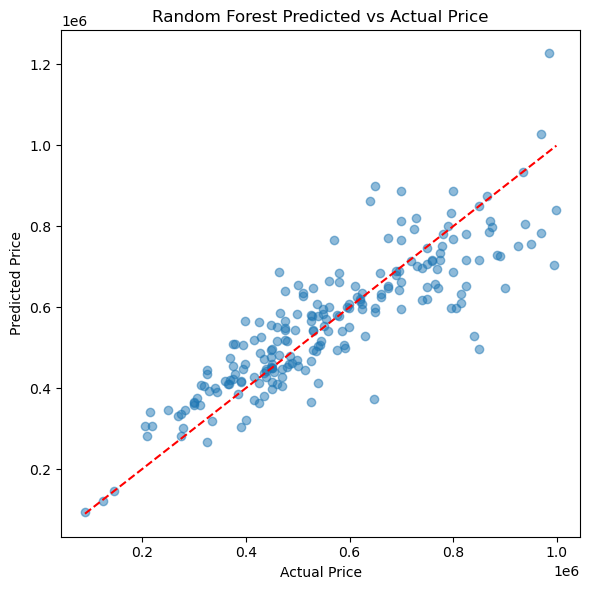

In [72]:
plt.figure(figsize=(6,6))
plt.scatter(y, model.predict(x), alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # 45° reference line
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest Predicted vs Actual Price")
plt.tight_layout()
plt.show()

### Anomaly Detection
---

In [110]:
# Predicted vs actual
data['pred_price'] = model.predict(x)
data['residual'] = y - data['pred_price']

# Detect anomalies based on residual magnitude 
upr_threshold = data['residual'].mean() + 2 * data['residual'].std() # (+2 std dev from mean)
lwr_threshold = data['residual'].mean() - 2 * data['residual'].std() # (-2 std dev from mean)
data['price_anomaly'] = ((data['residual'] > upr_threshold) |  (data['residual'] < -upr_threshold)).astype(int)

In [111]:
outliers = data[data['price_anomaly'] == 1]
print(f"Detected {len(outliers)} anomalies out of {len(data)} listings.")

Detected 13 anomalies out of 213 listings.


In [112]:
# Separate anomalies and normal homes
anomalies = data[data['price_anomaly'] == 1]

# Classify anomalies as high or low based on price deviation
anomalies['anomaly_type'] = anomalies['residual'].apply(
    lambda x: 'High-price anomaly' if x > upr_threshold else
              'Low-price anomaly'if x < lwr_threshold else
                'Normal-price anomaly')

# Check counts
anomalies['anomaly_type'].value_counts()

C:\Users\tanne\AppData\Local\Temp\ipykernel_25544\2192367113.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anomalies['anomaly_type'] = anomalies['residual'].apply(


anomaly_type
High-price anomaly    8
Low-price anomaly     5
Name: count, dtype: int64

In [113]:
# Identify the anomalies by matching indices
anomalies_data = data.loc[anomalies.index, ['URL','CITY', 'YEAR BUILT', 'DAYS ON MARKET', 'PRICE', 'SQUARE FEET', 'BEDS', 'BATHS',
        'LOT SIZE', 'HOA/MONTH', 'LATITUDE', 'LONGITUDE']].copy()

# Add the anomaly type from the anomalies DataFrame
anomalies_data['anomaly_type'] = anomalies['anomaly_type'].values

# Preview the result
anomalies_data.head()

,URL,CITY,YEAR BUILT,DAYS ON MARKET,PRICE,SQUARE FEET,BEDS,BATHS,LOT SIZE,HOA/MONTH,LATITUDE,LONGITUDE,anomaly_type
8,https://www.redfin.com/UT/Salt-Lake-City/35-E-...,Salt Lake City,2011.0,1.0,849900.0,1295.0,1.0,1.5,435.0,725.000000,40.767656,-111.890365,High-price anomaly
21,https://www.redfin.com/UT/Salt-Lake-City/577-E...,Salt Lake City,1939.0,1.0,985000.0,5341.0,5.0,5.5,15681.0,463.142857,40.784437,-111.872416,Low-price anomaly
63,https://www.redfin.com/UT/Salt-Lake-City/627-N...,Salt Lake City,2025.0,6.0,899900.0,2295.0,3.0,2.5,3920.0,90.000000,40.782552,-111.892240,High-price anomaly
117,https://www.redfin.com/UT/Salt-Lake-City/18-E-...,Salt Lake City,1929.0,13.0,650000.0,3150.0,5.0,3.0,4791.0,463.142857,40.776240,-111.877564,Low-price anomaly
123,https://www.redfin.com/UT/Salt-Lake-City/839-E...,Salt Lake City,1912.0,13.0,647000.0,1007.0,1.0,1.0,435.0,475.000000,40.769556,-111.866805,High-price anomaly


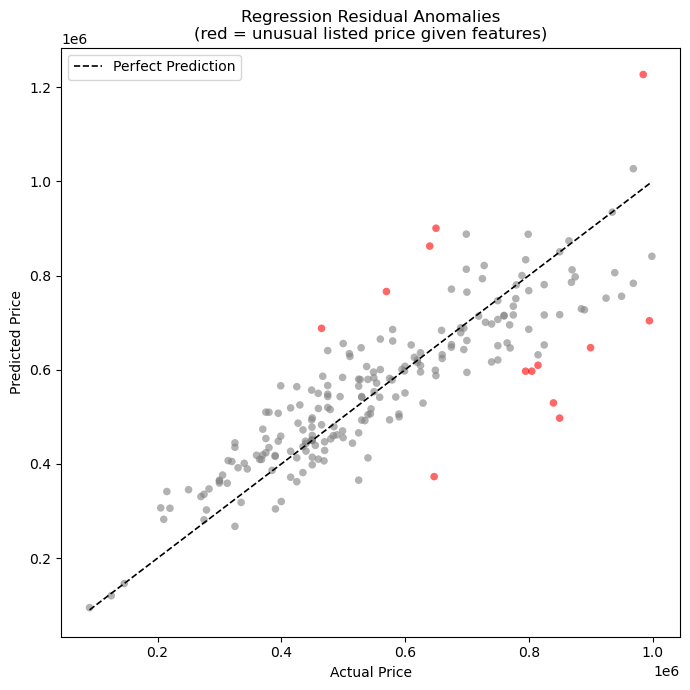

In [114]:
# Scatter plot: Actual vs Predicted
plt.figure(figsize=(7, 7))

# Color points by anomaly flag (1=red, 0=grey)
colors = data['price_anomaly'].map({1: 'red', 0: 'grey'})

plt.scatter(data['PRICE'], data['pred_price'], c=colors, alpha=0.6, s=30, edgecolors='none')

# 45° reference line
plt.plot(
    [data['PRICE'].min(), data['PRICE'].max()],
    [data['PRICE'].min(), data['PRICE'].max()],
    'k--', lw=1.2, label='Perfect Prediction'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Regression Residual Anomalies\n(red = unusual listed price given features)")
plt.legend()
plt.tight_layout()
plt.show()


### Map of Detected Anomalies
---

In [115]:
# Keep all columns you will reference later
cols_needed = ['LATITUDE', 'LONGITUDE', 'URL', 'anomaly_type', 'PRICE', 'SQUARE FEET']
plot_df = anomalies_data[cols_needed].copy()

# Drop rows missing coordinates
plot_df = plot_df.dropna(subset=['LATITUDE', 'LONGITUDE'])

# Map center
center = [plot_df['LATITUDE'].mean(), plot_df['LONGITUDE'].mean()]

# Color map (added green for normal)
color_map = {
    'High-price anomaly': 'red',
    'Low-price anomaly': 'blue',
    'Normal-priced anomaly': 'green',
    'Unknown': 'gray'
}

# Base map
m = folium.Map(location=center, zoom_start=10, tiles='OpenStreetMap')

# Layers with clustering (added "Normal-priced anomaly")
layers = {}
for atype in ['High-price anomaly', 'Low-price anomaly', 'Normal-priced anomaly', 'Unknown']:
    fg = folium.FeatureGroup(name=atype, show=True)
    mc = MarkerCluster(name=f"{atype} cluster")
    mc.add_to(fg)
    fg.add_to(m)
    layers[atype] = mc

# Add markers
for _, row in plot_df.iterrows():
    raw = row.get('anomaly_type')
    atype = 'Unknown' if (raw is None or pd.isna(raw) or str(raw).strip() == '') else str(raw).strip()
    if atype not in layers:
        atype = 'Unknown'

    price = row.get('PRICE', np.nan)
    sqft  = row.get('SQUARE FEET', np.nan)
    color = color_map.get(atype, 'gray')

    tooltip_text = (
        f"{atype} • ${price:,.0f} • {int(sqft):,} sqft"
        if np.isfinite(price) and np.isfinite(sqft)
        else f"{atype}"
    )
    tooltip = folium.Tooltip(tooltip_text)

    popup_html = f"""
    <div style="font-size:14px;">
      <b>{atype}</b><br>
      Price: {'${:,.0f}'.format(price) if np.isfinite(price) else 'N/A'}<br>
      Sq Ft: {'{:,.0f}'.format(sqft) if np.isfinite(sqft) else 'N/A'}<br>
      <a href="{row.get('URL','')}" target="_blank">Open Redfin listing</a>
    </div>
    """
    popup = folium.Popup(popup_html, max_width=300)

    folium.CircleMarker(
        location=[row['LATITUDE'], row['LONGITUDE']],
        radius=6,
        color=color,
        fill=True,
        fill_opacity=0.85,
        popup=popup,
        tooltip=tooltip
    ).add_to(layers[atype])

folium.LayerControl(collapsed=False).add_to(m)

In [116]:
# Change path where the map will save
%cd C:/Users/tanne/OneDrive/Desktop/Fun Statistical Coding Practice/Utah Housing Anomaly Detection
# Save to file (open in a browser)
m.save("utah_anomalies_map.html")
print("Saved: utah_anomalies_map.html")

C:\Users\tanne\OneDrive\Desktop\Fun Statistical Coding Practice\Utah Housing Anomaly Detection
Saved: utah_anomalies_map.html


In [117]:
# Display Map
m